# Коэффициенты АПЛ: описание данных и базовый анализ

Годовой проект «Система обнаружения аномальных движений линии между букмекерами». Первая выгрузка данных и её базовый обзор.

Для запуска положите `epl_odds_2026-09-12_19.csv` в одну папку с ноутбуком. Нужны только `pandas`, `numpy` и `matplotlib`.

## Данные

- **Источник:** OddsPapi API, выгрузка 6–8 октября 2026.
- **Охват:** 16 матчей Английской Премьер-лиги 12–19 сентября 2026; букмекеры Pinnacle, Singbet, SBOBET, bet365; рынки 1X2 и тотал 2.5.
- **Период:** от открытия линии (примерно за 2 недели до матча) до конца матча.
- **Одна строка = одно обновление коэффициента:** матч × букмекер × рынок × исход × момент времени. Всего 70 402 строки.
- **Время** везде в UTC (московское = UTC + 3).

### Столбцы

| Столбец | Описание |
|---|---|
| `fixture_id` | ID матча в OddsPapi |
| `match` | «Хозяева — Гости» |
| `kickoff` | Плановое время начала матча |
| `stage` | `prematch` — до начала матча, `live` — во время матча |
| `hours_to_kickoff` | Сколько часов оставалось до начала; отрицательное значение = матч уже идёт |
| `ts` | Момент обновления коэффициента (до миллисекунд) |
| `bookmaker` | `pinnacle`, `singbet`, `sbobet`, `bet365` |
| `market` | `1x2` — исход матча, `total_2.5` — тотал голов 2.5 |
| `outcome` | `home` (П1), `draw` (Х), `away` (П2), `over_2.5` (ТБ), `under_2.5` (ТМ) |
| `price` | Десятичный коэффициент |
| `implied_prob` | `1 / price`: вероятность с учётом маржи букмекера |
| `price_changed` | `True`, если цена отличается от предыдущей записи этого исхода у этого букмекера |
| `is_active` | `False` = линия в этот момент снята, цена не действует |
| `pinnacle_limit` | Максимальная ставка у Pinnacle; у остальных букмекеров пусто |

### Что учесть при работе

- **Почти половина строк — live.** Для анализа линии до матча берите `stage == "prematch"`.
- **Не каждая строка — изменение цены.** bet365 часто снимает и возвращает линию без изменения цены. Для анализа движений используйте `price_changed` и `is_active`.
- **SBOBET открывает линию поздно,** примерно за 2–3 дня до матча.
- **William Hill** был в запросе, но API вернул пустые данные.
- **При очистке** удалена 601 служебная запись bet365 с ценой 1.0 (все во время матча); время приведено к единому формату.
- **Подозрительная запись:** Crystal Palace — Ipswich, bet365, П1. За 10 минут до матча цена 2.15, через 4 минуты снова 1.81, хотя у остальных около 2.20. В данных оставлена.
- **Выборка маленькая:** 16 матчей, выводы предварительные.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False,
})
# у каждого букмекера свой цвет во всех графиках
BOOKS = ["pinnacle", "singbet", "sbobet", "bet365"]
COL = {"pinnacle": "#2a78d6", "singbet": "#eb6834", "sbobet": "#1baf7a", "bet365": "#eda100"}
# русские подписи для графиков
MARKET_RU = {"1x2": "1X2", "total_2.5": "Тотал 2.5"}
OUTCOME_RU = {"home": "П1", "draw": "Х", "away": "П2", "over_2.5": "ТБ 2.5", "under_2.5": "ТМ 2.5"}

## 1. Загружаем таблицу

In [2]:
df = pd.read_csv("epl_odds_2026-09-12_19.csv", parse_dates=["kickoff", "ts"])
# время в таблице в UTC
df["kickoff"] = df["kickoff"].dt.tz_localize("UTC")
df["ts"] = df["ts"].dt.tz_localize("UTC")

# для графиков переводим рынки, исходы и стадии на русский
df["market"] = df["market"].map(MARKET_RU)
df["outcome"] = df["outcome"].map(OUTCOME_RU)
df["stage"] = df["stage"].map({"prematch": "до матча", "live": "во время матча"})

print("Размер таблицы:", df.shape)
df.head()

Размер таблицы: (70402, 14)


,fixture_id,match,kickoff,stage,hours_to_kickoff,ts,bookmaker,market,outcome,price,implied_prob,price_changed,is_active,pinnacle_limit
0,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00+00:00,до матча,309.5254,2026-08-30 16:28:28.448000+00:00,bet365,1X2,П2,4.750,0.21053,True,True,NaN
1,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00+00:00,до матча,306.9428,2026-08-30 19:03:25.891000+00:00,bet365,1X2,П2,4.333,0.23079,True,True,NaN
2,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00+00:00,до матча,305.6228,2026-08-30 20:22:37.772000+00:00,bet365,1X2,П2,4.333,0.23079,False,False,NaN
3,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00+00:00,до матча,305.5252,2026-08-30 20:28:29.226000+00:00,bet365,1X2,П2,4.333,0.23079,False,True,NaN
4,id1000001772221252,Aston Villa — Nottingham Forest,2026-09-12 14:00:00+00:00,до матча,302.5306,2026-08-30 23:28:10.007000+00:00,bet365,1X2,П2,4.333,0.23079,False,False,NaN


In [3]:
print("Матчей:", df["fixture_id"].nunique())
print("Букмекеров:", df["bookmaker"].nunique(), sorted(df["bookmaker"].unique()))
print("Период обновлений:", df["ts"].min().strftime("%Y-%m-%d"), "—", df["ts"].max().strftime("%Y-%m-%d"))
print("Матчи играются:", df["kickoff"].min().strftime("%Y-%m-%d"), "—", df["kickoff"].max().strftime("%Y-%m-%d"))
print()
print("Пропуски по столбцам:")
print(df.isna().sum()[lambda s: s > 0])
print()
print("Полных дубликатов строк:", df.duplicated().sum())
print("Лимит ставки есть только у:", df.loc[df["pinnacle_limit"].notna(), "bookmaker"].unique())

Матчей: 16
Букмекеров: 4 ['bet365', 'pinnacle', 'sbobet', 'singbet']
Период обновлений: 2026-08-30 — 2026-09-19
Матчи играются: 2026-09-12 — 2026-09-19

Пропуски по столбцам:
pinnacle_limit    44659
dtype: int64

Полных дубликатов строк: 0
Лимит ставки есть только у: ['pinnacle']


**Качество данных:** дубликатов нет, единственный столбец с пропусками — `pinnacle_limit` (максимальная ставка). Его отдаёт только Pinnacle, у остальных букмекеров он пустой, и это нормально. При очистке убраны 601 служебная запись bet365 с ценой 1.0 (заглушки во время матча). William Hill запрашивали, но API вернул по нему пустой ответ.

## 2. Сколько данных по каждому букмекеру

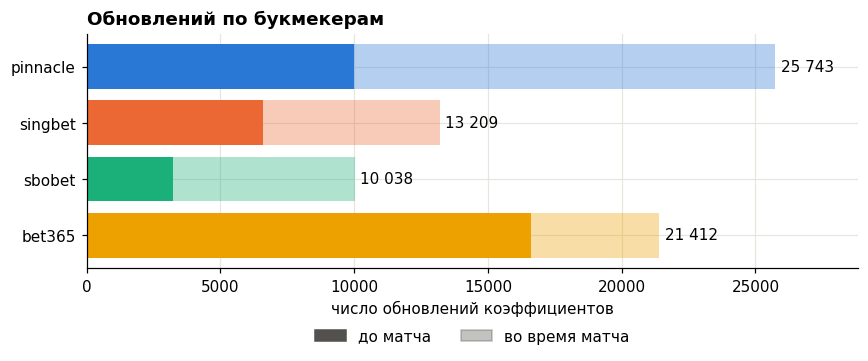

Доля обновлений во время матча (live): 48%


In [4]:
counts = df.pivot_table(index="bookmaker", columns="stage", values="price", aggfunc="size").loc[BOOKS[::-1]]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(counts.index, counts["до матча"], color=[COL[b] for b in counts.index], label="до матча")
ax.barh(counts.index, counts["во время матча"], left=counts["до матча"],
        color=[COL[b] for b in counts.index], alpha=0.35, label="во время матча")
for i, b in enumerate(counts.index):
    ax.text(counts.loc[b].sum() + 200, i, f"{counts.loc[b].sum():,}".replace(",", " "), va="center")
ax.set_xlabel("число обновлений коэффициентов")
ax.set_title("Обновлений по букмекерам")
ax.set_xlim(0, counts.sum(axis=1).max() * 1.12)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#52514e", label="до матча"), Patch(color="#52514e", alpha=0.35, label="во время матча")],
          loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
fig.tight_layout(); plt.show()

print(f"Доля обновлений во время матча (live): {(df['stage'] == 'во время матча').mean():.0%}")

Почти половина записей приходится на **live**, то есть на время, когда матч уже идёт. Для задачи (движение линии до матча) их нужно отфильтровать. Дальше почти везде берём только предматчевые котировки.

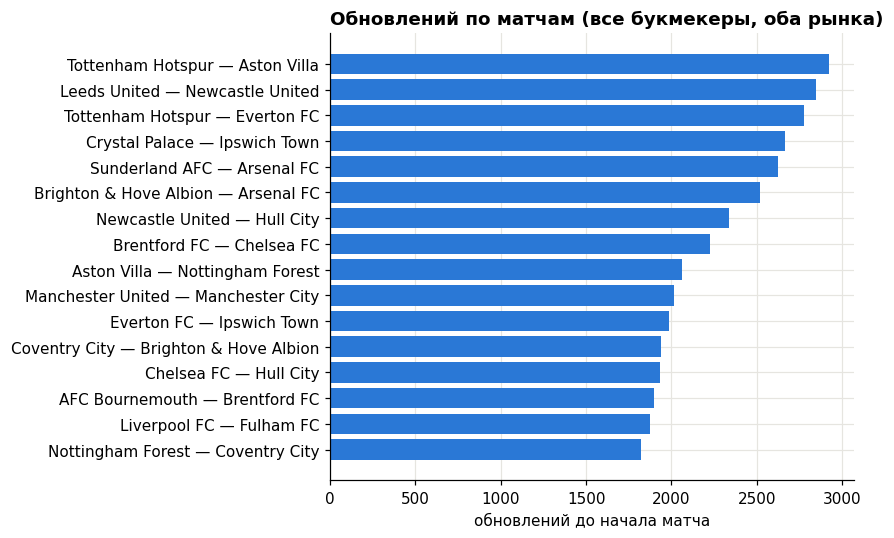

In [5]:
pre = df[df["stage"] == "до матча"].copy()

per_match = pre.groupby("match").size().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(per_match.index, per_match.values, color="#2a78d6")
ax.set_xlabel("обновлений до начала матча")
ax.set_title("Обновлений по матчам (все букмекеры, оба рынка)")
fig.tight_layout(); plt.show()

## 3. Когда появляются обновления

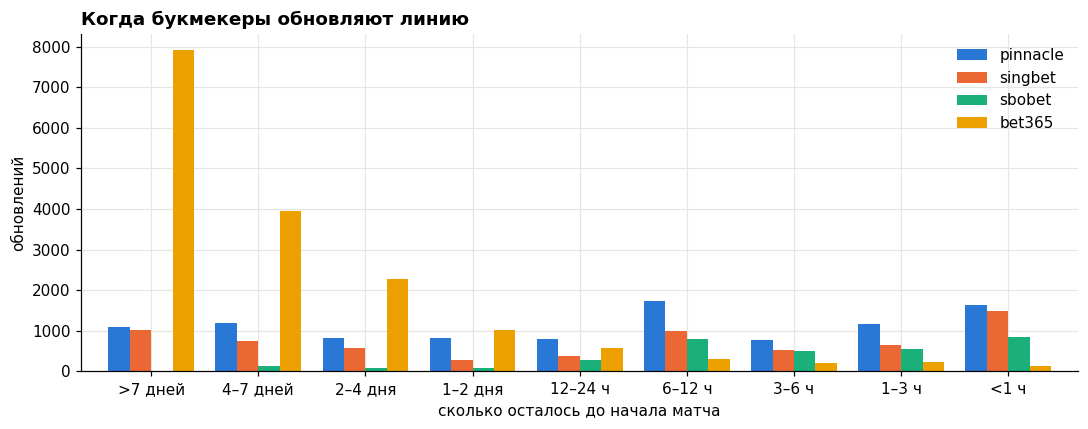

In [6]:
# сколько обновлений приходится на каждый интервал до начала матча
bins = [0, 1, 3, 6, 12, 24, 48, 96, 168, 400]
labels = ["<1 ч", "1–3 ч", "3–6 ч", "6–12 ч", "12–24 ч", "1–2 дня", "2–4 дня", "4–7 дней", ">7 дней"]
pre["interval"] = pd.cut(pre["hours_to_kickoff"], bins=bins, labels=labels)

by_interval = pre.pivot_table(index="interval", columns="bookmaker", values="price",
                              aggfunc="size", observed=False)[BOOKS].iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4))
by_interval.plot(kind="bar", ax=ax, color=[COL[b] for b in BOOKS], width=0.8)
ax.set_xlabel("сколько осталось до начала матча")
ax.set_ylabel("обновлений")
ax.set_title("Когда букмекеры обновляют линию")
ax.tick_params(axis="x", rotation=0)
ax.legend(title=None)
fig.tight_layout(); plt.show()

Обратите внимание, что интервалы разной длины: «<1 ч» — это один час, а «>7 дней» — больше недели. У Pinnacle, Singbet и SBOBET за последний час до матча обновлений больше, чем за всю первую неделю: линия активно «живёт» в последние сутки.

bet365 выглядит наоборот, но это обман зрения: большая часть его ранних записей — снятие и возврат линии (`active` = False/True) без изменения цены. Проверка ниже.

SBOBET выставляет линию поздно, примерно за 2–3 дня до матча, поэтому на дальних горизонтах его нет.

In [7]:
# у каждого букмекера: какая доля записей реально меняет цену и какая доля — снятие линии
# столбец price_changed уже посчитан в чистой таблице
check = pre.groupby("bookmaker").agg(
    записей=("price", "size"),
    цена_изменилась=("price_changed", "mean"),
    линия_снята=("is_active", lambda x: (~x).mean()),
).loc[BOOKS]
check[["цена_изменилась", "линия_снята"]] = (check[["цена_изменилась", "линия_снята"]] * 100).round(0)
check   # доли в процентах

,записей,цена_изменилась,линия_снята
bookmaker,,,
pinnacle,10007,85.0,2.0
singbet,6611,72.0,11.0
sbobet,3236,99.0,1.0
bet365,16592,28.0,36.0


## 4. Какие бывают коэффициенты

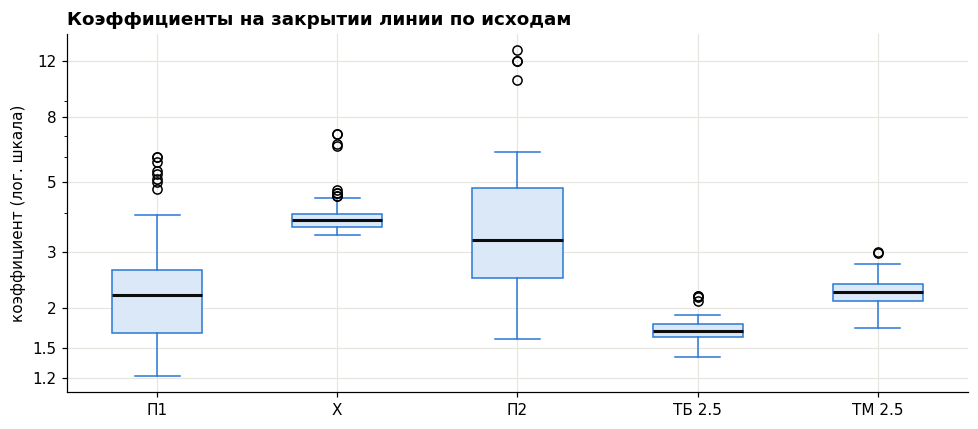

,min,50%,max
outcome,,,
П1,1.22,2.20,6.00
Х,3.40,3.79,7.10
П2,1.60,3.28,13.00
ТБ 2.5,1.40,1.70,2.18
ТМ 2.5,1.73,2.25,3.00


In [8]:
# последний предматчевый коэффициент («закрытие линии») по каждому букмекеру, матчу и исходу
live_pre = pre[pre["is_active"]].sort_values("ts")
closing = live_pre.groupby(["match", "bookmaker", "market", "outcome"], as_index=False).last()

order = ["П1", "Х", "П2", "ТБ 2.5", "ТМ 2.5"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([closing.loc[closing["outcome"] == o, "price"] for o in order], widths=0.5,
           patch_artist=True, boxprops=dict(facecolor="#dbe8f8", color="#2a78d6"),
           medianprops=dict(color="#0b0b0b", lw=2), whiskerprops=dict(color="#2a78d6"), capprops=dict(color="#2a78d6"))
ax.set_xticks(range(1, len(order) + 1), order)
ax.set_yscale("log")
ax.set_yticks([1.2, 1.5, 2, 3, 5, 8, 12]); ax.set_yticklabels(["1.2", "1.5", "2", "3", "5", "8", "12"])
ax.set_ylabel("коэффициент (лог. шкала)")
ax.set_title("Коэффициенты на закрытии линии по исходам")
fig.tight_layout(); plt.show()

closing.groupby("outcome")["price"].describe()[["min", "50%", "max"]].loc[order].round(2)

Ничья обычно стоит 3,4–4,5 (медиана ~3,8). Коэффициенты на победу разбросаны сильно: от явных фаворитов (~1,2–1,4) до больших андердогов (8+). На тотал 2.5 «больше» обычно дешевле, чем «меньше»: в АПЛ рынок чаще ждёт 3+ гола.

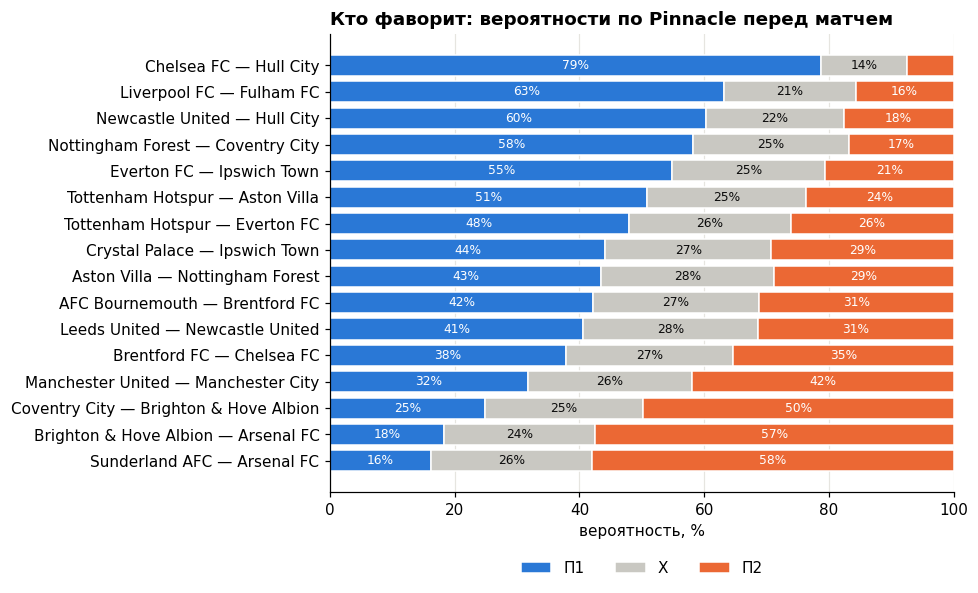

In [9]:
# вероятности исходов по мнению Pinnacle: 1/коэф, нормированные, чтобы сумма = 100%
pin = closing[(closing["bookmaker"] == "pinnacle") & (closing["market"] == "1X2")]
pin = pin.pivot(index="match", columns="outcome", values="price")[["П1", "Х", "П2"]]
prob = (1 / pin).div((1 / pin).sum(axis=1), axis=0) * 100
prob = prob.sort_values("П1")

fig, ax = plt.subplots(figsize=(9, 5.5))
left = np.zeros(len(prob))
for o, c in zip(["П1", "Х", "П2"], ["#2a78d6", "#c9c8c2", "#eb6834"]):
    ax.barh(prob.index, prob[o], left=left, color=c, label=o, edgecolor="white")
    for i, v in enumerate(prob[o]):
        if v > 8:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if o != "Х" else "#0b0b0b")
    left += prob[o].values
ax.set_xlim(0, 100); ax.set_xlabel("вероятность, %")
ax.set_title("Кто фаворит: вероятности по Pinnacle перед матчем")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

## 5. Сравниваем букмекеров

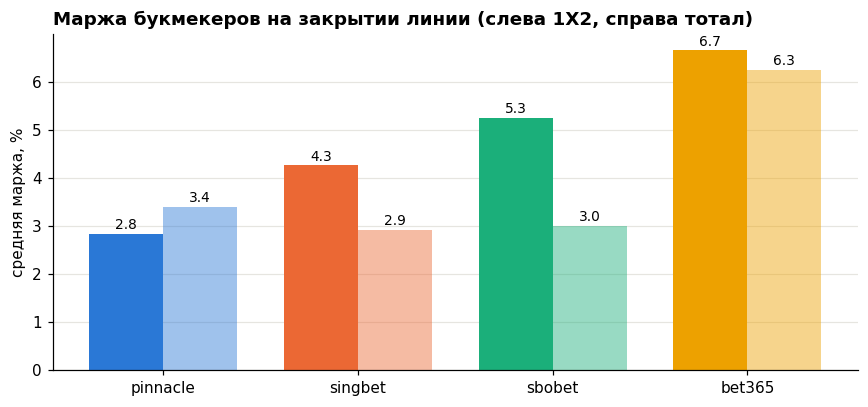

In [10]:
# маржа = сумма (1/коэф) по всем исходам рынка − 1
closing["inv"] = 1 / closing["price"]
margin = closing.groupby(["bookmaker", "market", "match"])["inv"].sum().sub(1).mul(100)
margin = margin.groupby(["bookmaker", "market"]).mean().unstack().loc[BOOKS]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(BOOKS)); w = 0.38
ax.bar(x - w / 2, margin["1X2"], w, color=[COL[b] for b in BOOKS], label="1X2")
ax.bar(x + w / 2, margin["Тотал 2.5"], w, color=[COL[b] for b in BOOKS], alpha=0.45, label="Тотал 2.5")
for i, b in enumerate(BOOKS):
    ax.text(i - w / 2, margin.loc[b, "1X2"] + 0.1, f"{margin.loc[b, '1X2']:.1f}", ha="center", fontsize=9)
    ax.text(i + w / 2, margin.loc[b, "Тотал 2.5"] + 0.1, f"{margin.loc[b, 'Тотал 2.5']:.1f}", ha="center", fontsize=9)
ax.set_xticks(x, BOOKS)
ax.set_ylabel("средняя маржа, %")
ax.set_title("Маржа букмекеров на закрытии линии (слева 1X2, справа тотал)")
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

**Маржа** — это комиссия букмекера, заложенная в коэффициенты. У честной монетки оба исхода стоили бы 2,00; букмекер ставит, например, 1,95 и 1,95, и сумма 1/коэф выходит больше 100%. Чем ниже маржа, тем «острее» букмекер. У Pinnacle она минимальная, у bet365 — максимальная. Поэтому Pinnacle обычно считают ориентиром «справедливой» цены.

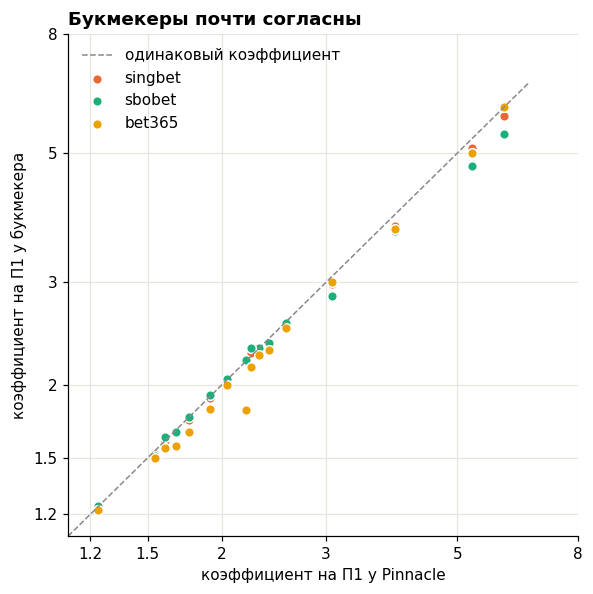

In [11]:
# согласны ли букмекеры друг с другом: коэффициент на П1 у каждого против Pinnacle
p1 = closing[closing["outcome"] == "П1"].pivot(index="match", columns="bookmaker", values="price")

fig, ax = plt.subplots(figsize=(5.5, 5.5))
lim = [1.1, p1.max().max() * 1.1]
ax.plot(lim, lim, color="#8a8984", lw=1, ls="--", label="одинаковый коэффициент")
for b in ["singbet", "sbobet", "bet365"]:
    ax.scatter(p1["pinnacle"], p1[b], color=COL[b], s=40, edgecolor="white", label=b)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.minorticks_off()
ticks = [1.2, 1.5, 2, 3, 5, 8]
ax.set_xticks(ticks, [str(t) for t in ticks]); ax.set_yticks(ticks, [str(t) for t in ticks])
ax.set_xlabel("коэффициент на П1 у Pinnacle"); ax.set_ylabel("коэффициент на П1 у букмекера")
ax.set_title("Букмекеры почти согласны")
ax.legend()
fig.tight_layout(); plt.show()

Точки лежат почти на диагонали: в оценке матча букмекеры почти не расходятся. Чуть ниже диагонали чаще всего bet365: у него выше маржа, и коэффициенты в среднем немного меньше. Одна точка bet365 заметно ниже диагонали (≈1,8 против 2,2 у Pinnacle): это Crystal Palace — Ipswich. За 10 минут до матча bet365 поднял коэффициент до 2,15 вслед за рынком, а через 4 минуты вернул 1,81. Похоже на сбой в данных или откат цены. Такие выбросы стоит проверять вручную, а детектор должен уметь их отсеивать.

Поэтому **интересны не сами уровни, а моменты, когда кто-то из букмекеров заметно отходит от остальных**: это и будет искать детектор.

## 6. Как меняется линия

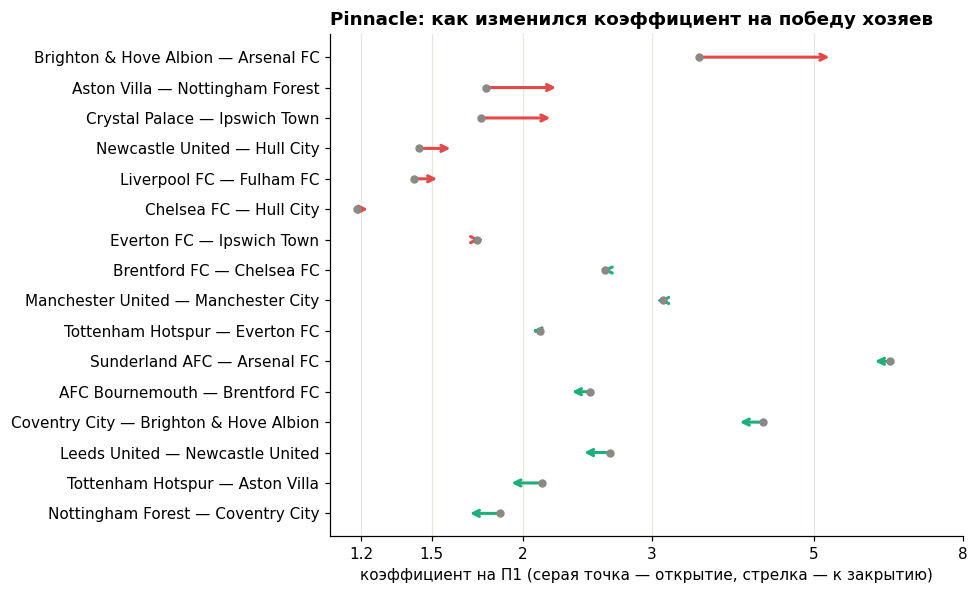

,открытие,закрытие,"изменение, %"
match,,,
Nottingham Forest — Coventry City,1.86,1.68,-10.04
Tottenham Hotspur — Aston Villa,2.12,1.91,-9.95
Leeds United — Newcastle United,2.63,2.40,-8.75
Coventry City — Brighton & Hove Albion,4.26,3.92,-7.98
AFC Bournemouth — Brentford FC,2.47,2.31,-6.48
Sunderland AFC — Arsenal FC,6.36,6.00,-5.66
Tottenham Hotspur — Everton FC,2.11,2.04,-3.32
Manchester United — Manchester City,3.11,3.07,-1.29
Brentford FC — Chelsea FC,2.59,2.57,-0.77


In [12]:
# коэффициент на П1 у Pinnacle: в момент открытия линии и перед матчем
pin_p1 = live_pre[(live_pre["bookmaker"] == "pinnacle") & (live_pre["outcome"] == "П1")]
oc = pin_p1.groupby("match")["price"].agg(открытие="first", закрытие="last")
oc["изменение, %"] = (oc["закрытие"] / oc["открытие"] - 1) * 100
oc = oc.sort_values("изменение, %")

fig, ax = plt.subplots(figsize=(9, 5.5))
for i, (m, r) in enumerate(oc.iterrows()):
    c = "#1baf7a" if r["закрытие"] < r["открытие"] else "#e34948"
    ax.annotate("", xy=(r["закрытие"], i), xytext=(r["открытие"], i),
                arrowprops=dict(arrowstyle="->", color=c, lw=2))
    ax.scatter(r["открытие"], i, color="#8a8984", s=20, zorder=3)
ax.set_yticks(range(len(oc)), oc.index)
ax.set_xscale("log"); ax.minorticks_off()
ticks = [1.2, 1.5, 2, 3, 5, 8]; ax.set_xticks(ticks, [str(t) for t in ticks])
ax.set_xlabel("коэффициент на П1 (серая точка — открытие, стрелка — к закрытию)")
ax.set_title("Pinnacle: как изменился коэффициент на победу хозяев")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

oc.round(2)

Зелёная стрелка влево — коэффициент на хозяев упал (на них ставили, или вышли новости в их пользу), красная вправо — вырос. От открытия до матча коэффициент на П1 у Pinnacle в медиане сдвигается примерно на 8%. Но у трёх матчей сдвиг больше 25%: Brighton — Arsenal (+52%), Aston Villa — Nottingham Forest и Crystal Palace — Ipswich (по ~+26%). Такие матчи стоит разобрать отдельно: найти, когда именно сдвинулась линия и что в этот момент было в новостях.

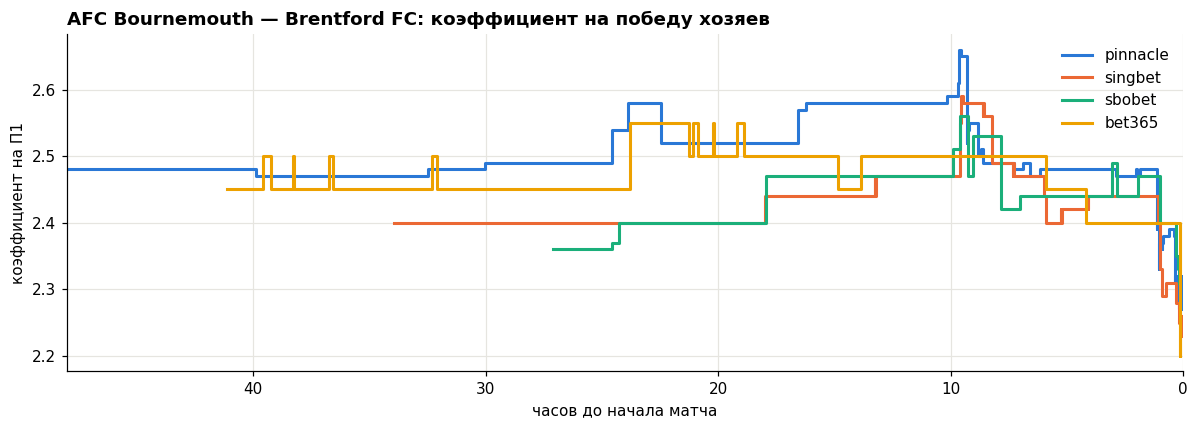

In [13]:
# как двигался коэффициент на П1 в одном матче (меняйте MATCH_N)
MATCH_N = 0
HOURS = 48     # сколько последних часов до матча показывать

m_name = sorted(pre["match"].unique())[MATCH_N]
m = live_pre[(live_pre["match"] == m_name) & (live_pre["outcome"] == "П1") & (live_pre["hours_to_kickoff"] <= HOURS)]

fig, ax = plt.subplots(figsize=(11, 4))
for b in BOOKS:
    s = m[m["bookmaker"] == b]
    if len(s):
        ax.step(s["hours_to_kickoff"], s["price"], where="post", color=COL[b], lw=2, label=b)
ax.set_xlim(HOURS, 0)
ax.set_xlabel("часов до начала матча")
ax.set_ylabel("коэффициент на П1")
ax.set_title(f"{m_name}: коэффициент на победу хозяев")
ax.legend()
fig.tight_layout(); plt.show()

## Итоги

- **Объём:** 16 матчей АПЛ, 4 букмекера, рынки 1X2 и тотал 2.5, ~71 тыс. обновлений. Половина из них — live, для задачи их отбрасываем.
- **Качество:** дубликатов нет, пропуски только в `limit` (его отдаёт лишь Pinnacle). William Hill не вернул данных. SBOBET открывает линию поздно.
- **Активность:** основная часть обновлений — в последние сутки и особенно в последний час до матча.
- **Букмекеры:** по уровню коэффициентов почти совпадают, отличаются маржой (Pinnacle минимальная, bet365 максимальная) и скоростью реакции.
- **Движение:** от открытия до матча коэффициент на П1 в медиане сдвигается на ~8%, у трёх матчей — больше чем на 25%.